# CS-781 Phase 1 — Architecture 2: encoder–decoder v2 from scratch (new BPE tokenizer)

In this notebook I train my encoder–decoder legal language model: the encoder reads the 512-word prompt and the decoder writes the 128-word continuation.

**What changed from my v1.** v1 decoded with plain greedy search and fell into loops ("The delay is a ground for delay. The delay is ..."), trained for about 3 h on only 250k pairs taken from the first documents of each file, and used slow `DataParallel` generation without a KV cache.

**v2.**
* My own byte-level BPE (32k).
* About 90M parameters: 6 encoder + 6 decoder layers, d_model 640, 10 heads, shared embeddings.
* **Tail prefix**: the decoder also sees the last 64 prompt tokens; the loss is only on the continuation.
* More and more diverse training pairs: windows spread over documents, stride-sampled while streaming.
* DDP on both T4 GPUs with a time-budgeted cosine learning-rate schedule.
* KV-cached batched generation with repetition control; decoding settings are chosen by BERTScore on held-out validation prompts.
* Automatic fall-backs for out-of-memory errors and a single GPU.


In [1]:
# =====================================================================================
# 1. SETUP: paths, GPU check, tokenizer files, HF token, official test prompts
# =====================================================================================
import os, sys, time, json, glob, shutil, subprocess, math, random
NB_START = time.time()                          # the whole notebook is time-boxed from this moment

ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.path.abspath("./work")
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
CODE_DIR, DATA_DIR, RUN_DIR, TOK_DIR = [f"{WORK}/{d}" for d in ("ed2_code", "ed2_data", "ed2_run", "ed2_tokenizer")]
for d in (CODE_DIR, DATA_DIR, RUN_DIR, TOK_DIR):
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, CODE_DIR)
sys.path.insert(0, TOK_DIR)

import torch
N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", N_GPU)
for i in range(N_GPU):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} | {p.total_memory / 2**30:.1f} GiB")
assert N_GPU >= 1, "Turn on a GPU accelerator (T4 x2) in the notebook settings."
DEV = torch.device("cuda:0")

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ijson", "requests"], check=False)
import ijson
print("ijson backend:", ijson.backend, "(yajl2_c is the fast one)")

# ---- tokenizer files (my own from-scratch BPE) ----
def find_file(name):
    pats = [f"/kaggle/input/**/{name}", f"{WORK}/{name}", f"./{name}"]
    for pat in pats:
        hits = glob.glob(pat, recursive=True)
        if hits:
            return hits[0]
    return None

for fn in ("a1_tokenization.py", "vocab.json", "merges.txt"):
    src = find_file(fn)
    assert src, f"{fn} not found - attach the Kaggle dataset that contains it."
    try:
        shutil.copy(src, f"{TOK_DIR}/{fn}")
    except shutil.SameFileError:
        pass
from a1_tokenization import Tokenizer, normalize_text
tok = Tokenizer.load(TOK_DIR)
print("tokenizer loaded | vocab size:", tok.vocab_size)

# ---- HF token + official test prompts ----
HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception as e:
    print("(no HF secret found:", repr(e)[:80], ")")
HF_BASE = "https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/"

def load_test():
    for p in glob.glob("/kaggle/input/**/*.json", recursive=True) + glob.glob(f"{WORK}/test.json"):
        if os.path.basename(p).lower() in ("test.json", "phase1- test.json", "phase1-test.json"):
            d = json.load(open(p))
            if isinstance(d, dict) and "1" in d:
                return d, p
    import requests
    url = HF_BASE + "Phase_1_Pretraining/Test/test.json"
    r = requests.get(url, headers={"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}, timeout=120)
    r.raise_for_status()
    return r.json(), url

test_data, test_src = load_test()
print(f"official test prompts: {len(test_data)} (from {test_src})")

torch 2.11.0+cu128 | GPUs: 2
  GPU 0: Tesla T4 | 14.6 GiB
  GPU 1: Tesla T4 | 14.6 GiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 5.6 MB/s eta 0:00:00
ijson backend: yajl2_c (yajl2_c is the fast one)
tokenizer loaded | vocab size: 32000
official test prompts: 1000 (from /kaggle/input/datasets/amex786/test-json/test.json)


In [2]:
# =====================================================================================
# 2. MODEL CODE -> edmodel.py (encoder-decoder, KV-cache generation with repetition control)
# =====================================================================================
CODE_DIR = globals().get('CODE_DIR', '/kaggle/working/ed2_code')
with open(f'{CODE_DIR}/edmodel.py', 'w') as _f:
    _f.write(r'''"""Encoder-decoder Transformer language model (v2) - written from scratch in PyTorch.

Design (all trained from scratch, no pretrained weights, no HF model classes):
  * Pre-LN encoder (bidirectional) + Pre-LN decoder (causal self-attn + cross-attn)
  * ONE token-embedding matrix shared by encoder, decoder and the output head (weight tying)
  * learned absolute positions (separate tables for encoder and decoder)
  * "tail prefix": the decoder input is  [BOS] + last K prompt tokens + continuation.
    Loss is computed ONLY on the continuation (+EOS). This gives the decoder a local language-model
    context at the exact point where it must continue, while the encoder still sees the full prompt.
  * KV-cached batched generation with repetition controls (the v1 model looped with plain greedy).
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class EDConfig:
    vocab_size: int = 32000
    d_model: int = 640
    n_heads: int = 10
    d_ff: int = 2560
    n_enc_layers: int = 6
    n_dec_layers: int = 6
    enc_max_len: int = 1024
    dec_max_len: int = 352
    tail_k: int = 64
    dropout: float = 0.1
    label_smoothing: float = 0.05
    pad_id: int = 0
    bos_id: int = 1
    eos_id: int = 2
    unk_id: int = 3


class Attention(nn.Module):
    """Multi-head attention used for self- and cross-attention. mask: bool, True = may attend."""

    def __init__(self, d, h):
        super().__init__()
        assert d % h == 0, "d_model must be divisible by n_heads"
        self.h, self.dh = h, d // h
        self.q = nn.Linear(d, d)
        self.k = nn.Linear(d, d)
        self.v = nn.Linear(d, d)
        self.o = nn.Linear(d, d)

    def split(self, x):                       # (B,T,D) -> (B,H,T,Dh)
        b, t, _ = x.shape
        return x.view(b, t, self.h, self.dh).transpose(1, 2)

    def merge(self, x):                       # (B,H,T,Dh) -> (B,T,D)
        b, h, t, dh = x.shape
        return x.transpose(1, 2).reshape(b, t, h * dh)

    def kv(self, x):
        return self.split(self.k(x)), self.split(self.v(x))

    def attend(self, q, k, v, mask=None, causal=False):
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal)
        return self.o(self.merge(out))

    def forward(self, x, mem=None, mask=None, causal=False):
        q = self.split(self.q(x))
        k, v = self.kv(x if mem is None else mem)
        return self.attend(q, k, v, mask, causal)


class FFN(nn.Module):
    def __init__(self, d, dff, p):
        super().__init__()
        self.fc1 = nn.Linear(d, dff)
        self.fc2 = nn.Linear(dff, d)
        self.drop = nn.Dropout(p)

    def forward(self, x):
        return self.fc2(self.drop(F.gelu(self.fc1(x))))


class EncLayer(nn.Module):
    def __init__(self, c):
        super().__init__()
        d = c.d_model
        self.n1 = nn.LayerNorm(d)
        self.attn = Attention(d, c.n_heads)
        self.n2 = nn.LayerNorm(d)
        self.ffn = FFN(d, c.d_ff, c.dropout)
        self.drop = nn.Dropout(c.dropout)

    def forward(self, x, mask):
        x = x + self.drop(self.attn(self.n1(x), mask=mask))
        x = x + self.drop(self.ffn(self.n2(x)))
        return x


class DecLayer(nn.Module):
    def __init__(self, c):
        super().__init__()
        d = c.d_model
        self.n1 = nn.LayerNorm(d)
        self.self_attn = Attention(d, c.n_heads)
        self.n2 = nn.LayerNorm(d)
        self.cross = Attention(d, c.n_heads)
        self.n3 = nn.LayerNorm(d)
        self.ffn = FFN(d, c.d_ff, c.dropout)
        self.drop = nn.Dropout(c.dropout)

    def forward(self, x, mem, mask):          # training path (full sequence, causal)
        x = x + self.drop(self.self_attn(self.n1(x), causal=True))
        x = x + self.drop(self.cross(self.n2(x), mem=mem, mask=mask))
        x = x + self.drop(self.ffn(self.n3(x)))
        return x

    # ---- inference helpers (eval mode only) ----
    def prefill(self, x, ckv, mask):
        a = self.self_attn
        h = self.n1(x)
        q = a.split(a.q(h))
        k, v = a.kv(h)
        x = x + a.attend(q, k, v, causal=True)
        h = self.n2(x)
        q = self.cross.split(self.cross.q(h))
        x = x + self.cross.attend(q, ckv[0], ckv[1], mask=mask)
        x = x + self.ffn(self.n3(x))
        return x, (k, v)

    def step(self, x, cache, ckv, mask):      # x: (B,1,D)
        a = self.self_attn
        h = self.n1(x)
        q = a.split(a.q(h))
        k, v = a.kv(h)
        kk = torch.cat([cache[0], k], dim=2)
        vv = torch.cat([cache[1], v], dim=2)
        x = x + a.attend(q, kk, vv)
        h = self.n2(x)
        q = self.cross.split(self.cross.q(h))
        x = x + self.cross.attend(q, ckv[0], ckv[1], mask=mask)
        x = x + self.ffn(self.n3(x))
        return x, (kk, vv)


class EncDecLM(nn.Module):
    def __init__(self, c: EDConfig):
        super().__init__()
        self.c = c
        d = c.d_model
        self.tok = nn.Embedding(c.vocab_size, d, padding_idx=c.pad_id)   # shared: enc / dec / output head
        self.enc_pos = nn.Embedding(c.enc_max_len, d)
        self.dec_pos = nn.Embedding(c.dec_max_len, d)
        self.drop = nn.Dropout(c.dropout)
        self.enc_layers = nn.ModuleList([EncLayer(c) for _ in range(c.n_enc_layers)])
        self.enc_norm = nn.LayerNorm(d)
        self.dec_layers = nn.ModuleList([DecLayer(c) for _ in range(c.n_dec_layers)])
        self.dec_norm = nn.LayerNorm(d)
        self.apply(self._init)
        # GPT-2 style scaled init for the layers that write into the residual stream
        for l in self.enc_layers:
            std = 0.02 / math.sqrt(2 * c.n_enc_layers)
            nn.init.normal_(l.attn.o.weight, 0.0, std)
            nn.init.normal_(l.ffn.fc2.weight, 0.0, std)
        for l in self.dec_layers:
            std = 0.02 / math.sqrt(3 * c.n_dec_layers)
            nn.init.normal_(l.self_attn.o.weight, 0.0, std)
            nn.init.normal_(l.cross.o.weight, 0.0, std)
            nn.init.normal_(l.ffn.fc2.weight, 0.0, std)
        with torch.no_grad():
            self.tok.weight[c.pad_id].zero_()

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0.0, 0.02)
            nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, 0.02)

    # ---------------- building blocks ----------------
    def embed(self, ids, pos_emb, offset=0):
        t = ids.size(1)
        pos = torch.arange(offset, offset + t, device=ids.device)
        return self.drop(self.tok(ids) + pos_emb(pos).unsqueeze(0))

    def encode(self, src):
        mask = (src != self.c.pad_id)[:, None, None, :]          # (B,1,1,Ts) True = real token
        x = self.embed(src, self.enc_pos)
        for l in self.enc_layers:
            x = l(x, mask)
        return self.enc_norm(x), mask

    def decode_hidden(self, dec_in, mem, mask):
        x = self.embed(dec_in, self.dec_pos)
        for l in self.dec_layers:
            x = l(x, mem, mask)
        return self.dec_norm(x)

    def logits(self, h):
        return F.linear(h, self.tok.weight)                       # tied output head

    def forward(self, src, dec_in, labels, label_smoothing=None):
        """src (B,Ts) | dec_in (B,Td) | labels (B,Td) with -100 on ignored positions.
        Returns (mean CE over valid positions, number of valid positions)."""
        mem, mask = self.encode(src)
        h = self.decode_hidden(dec_in, mem, mask)
        valid = labels != -100
        lg = self.logits(h[valid]).float()
        ls = self.c.label_smoothing if label_smoothing is None else label_smoothing
        loss = F.cross_entropy(lg, labels[valid], label_smoothing=ls)
        return loss, valid.sum()

    @torch.no_grad()
    def cross_kv(self, mem):
        return [l.cross.kv(mem) for l in self.dec_layers]


def make_word_start_table(id_to_token, device):
    """bool[V]: True for tokens that begin a new whitespace-delimited word (token string starts with 'G-dot')."""
    return torch.tensor([t.startswith("\u0120") for t in id_to_token], dtype=torch.bool, device=device)


@torch.no_grad()
def generate(model, prompts, is_word_start, target_words=128, max_new=240, temperature=0.0, top_k=0,
             top_p=1.0, rep_penalty=1.0, no_repeat_ngram=0, use_cache=True, seed=None):
    """Batched generation. prompts: list of token-id lists (full prompt, no BOS/EOS).
    Returns a list of token-id lists, each cut so that it decodes to at most `target_words` words.
    temperature<=0 -> greedy. EOS/PAD/BOS/UNK are never generated (we stop on word count instead)."""
    model.eval()
    c = model.c
    dev = next(model.parameters()).device
    B = len(prompts)
    prompts = [list(p[-c.enc_max_len:]) for p in prompts]
    kk = min([c.tail_k] + [len(p) for p in prompts])
    te = max(len(p) for p in prompts)
    src = torch.full((B, te), c.pad_id, dtype=torch.long)
    for i, p in enumerate(prompts):
        src[i, :len(p)] = torch.tensor(p, dtype=torch.long)
    tails = [p[len(p) - kk:] for p in prompts]
    dec = torch.tensor([[c.bos_id] + t for t in tails], dtype=torch.long)
    src, dec = src.to(dev), dec.to(dev)

    gen = None
    if temperature > 0:
        gen = torch.Generator(device=dev)
        gen.manual_seed(0 if seed is None else int(seed))

    mem, mask = model.encode(src)
    if use_cache:
        ckv = model.cross_kv(mem)
        x = model.embed(dec, model.dec_pos, 0)
        caches = []
        for i, l in enumerate(model.dec_layers):
            x, cch = l.prefill(x, ckv[i], mask)
            caches.append(cch)
        h = model.dec_norm(x)[:, -1]
    else:
        h = model.decode_hidden(dec, mem, mask)[:, -1]

    V = c.vocab_size
    ar = torch.arange(B, device=dev)
    banned = torch.tensor([c.pad_id, c.bos_id, c.eos_id, c.unk_id], device=dev)
    seen = torch.zeros(B, V, dtype=torch.bool, device=dev)
    wc = torch.zeros(B, dtype=torch.long, device=dev)
    out = torch.zeros(B, max_new, dtype=torch.long, device=dev)
    ng = int(no_repeat_ngram)
    hist = [list(t) for t in tails]
    maps = [dict() for _ in range(B)]
    if ng > 1:
        for b in range(B):
            hb = hist[b]
            for i in range(len(hb) - ng + 1):
                maps[b].setdefault(tuple(hb[i:i + ng - 1]), set()).add(hb[i + ng - 1])

    cur = dec.size(1)
    n_out = 0
    for t in range(max_new):
        lg = model.logits(h).float()
        lg[:, banned] = float("-inf")
        if rep_penalty != 1.0:
            pen = torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty)
            lg = torch.where(seen, pen, lg)
        if ng > 1:
            for b in range(B):
                bs = maps[b].get(tuple(hist[b][-(ng - 1):]))
                if bs:
                    lg[b, list(bs)] = float("-inf")
        if temperature <= 0:
            nxt = lg.argmax(dim=-1)
        else:
            lg = lg / temperature
            if top_k > 0:
                kth = torch.topk(lg, min(top_k, V), dim=-1)[0][:, -1, None]
                lg = lg.masked_fill(lg < kth, float("-inf"))
            if top_p < 1.0:
                s_lg, s_idx = torch.sort(lg, descending=True, dim=-1)
                s_pr = torch.softmax(s_lg, dim=-1)
                remove = (s_pr.cumsum(dim=-1) - s_pr) > top_p
                s_lg = s_lg.masked_fill(remove, float("-inf"))
                lg = torch.full_like(lg, float("-inf")).scatter(1, s_idx, s_lg)
            nxt = torch.multinomial(torch.softmax(lg, dim=-1), 1, generator=gen).squeeze(1)
        out[:, t] = nxt
        seen[ar, nxt] = True
        wc += is_word_start[nxt].long()
        nl = nxt.tolist()
        for b in range(B):
            hist[b].append(nl[b])
            if ng > 1 and len(hist[b]) >= ng:
                maps[b].setdefault(tuple(hist[b][-ng:-1]), set()).add(hist[b][-1])
        n_out = t + 1
        if bool((wc > target_words).all()):
            break
        if use_cache:
            x = model.embed(nxt[:, None], model.dec_pos, cur)
            for i, l in enumerate(model.dec_layers):
                x, caches[i] = l.step(x, caches[i], ckv[i], mask)
            h = model.dec_norm(x)[:, 0]
        else:
            dec = torch.cat([dec, nxt[:, None]], dim=1)
            h = model.decode_hidden(dec, mem, mask)[:, -1]
        cur += 1

    ws = is_word_start.tolist()
    res = []
    for row in out[:, :n_out].tolist():
        cnt, cut = 0, len(row)
        for j, tid in enumerate(row):
            if ws[tid]:
                cnt += 1
                if cnt > target_words:
                    cut = j
                    break
        res.append(row[:cut])
    return res
''')
print('written', f'{CODE_DIR}/edmodel.py', len(open(f'{CODE_DIR}/edmodel.py').read()), 'chars')

written /kaggle/working/ed2_code/edmodel.py 12688 chars


In [3]:
# =====================================================================================
# 3. DATA CODE -> eddata.py (HF streaming, windowing, tokenization, batch builder)
# =====================================================================================
CODE_DIR = globals().get('CODE_DIR', '/kaggle/working/ed2_code')
with open(f'{CODE_DIR}/eddata.py', 'w') as _f:
    _f.write(r'''"""Data utilities for the encoder-decoder notebook (numpy only; no torch needed)."""
import os
import json
import time
import zlib
import random
import numpy as np

ENC_MAX = 1024          # encoder tokens kept per pair (left-truncated if longer)
TGT_MAX = 224           # continuation tokens kept per pair (longer pairs are skipped)
PROMPT_WORDS = 512
TARGET_WORDS = 128
WIN = PROMPT_WORDS + TARGET_WORDS
SRC_NAMES = ["acts", "high_courts", "supreme_court", "tribunals"]


# ----------------------------------------------------------------------------------------------
# streaming a huge JSON array (records read one by one, nothing is downloaded to disk)
# ----------------------------------------------------------------------------------------------
class _SafeReader:
    """urllib3 closes the HTTP stream right after the last byte; ijson then asks for one more chunk."""

    def __init__(self, raw):
        self.raw = raw

    def read(self, n=-1):
        try:
            return self.raw.read(n)
        except ValueError:
            if getattr(self.raw, "closed", False):
                return b""
            raise


def stream_docs(url, token=None):
    import requests
    import ijson
    headers = {"Authorization": f"Bearer {token}"} if token else {}
    r = requests.get(url, headers=headers, stream=True, timeout=(30, 300))
    r.raise_for_status()
    r.raw.decode_content = True
    try:
        for d in ijson.items(_SafeReader(r.raw), "item"):
            yield d
    finally:
        r.close()


# ----------------------------------------------------------------------------------------------
# one document -> (encoder tokens, continuation tokens) pairs
# ----------------------------------------------------------------------------------------------
def doc_to_pairs(text, tok, normalize_fn, rng, max_pairs, min_enc_tokens=64):
    """512 words -> encoder input, next 128 words -> target. Windows are spread over the whole
    document (random offset, at most `max_pairs` windows) so long documents do not dominate."""
    words = normalize_fn(text).split(" ")
    n = len(words)
    if n < WIN:
        return []
    off = 0 if rng.random() < 0.35 else rng.randrange(0, WIN)
    n_win = (n - off) // WIN
    if n_win < 1:
        off, n_win = 0, n // WIN
    idxs = list(range(n_win)) if n_win <= max_pairs else sorted(rng.sample(range(n_win), max_pairs))
    out = []
    for w in idxs:
        s = off + w * WIN
        enc_ids = tok.encode(" ".join(words[s:s + PROMPT_WORDS]), normalize=False)
        tgt_ids = tok.encode(" " + " ".join(words[s + PROMPT_WORDS:s + WIN]), normalize=False)   # leading space!
        if len(tgt_ids) > TGT_MAX or len(enc_ids) < min_enc_tokens:
            continue
        if len(enc_ids) > ENC_MAX:
            enc_ids = enc_ids[-ENC_MAX:]
        out.append((enc_ids, tgt_ids))
    return out


class _Store:
    def __init__(self, cap):
        self.cap = cap
        self.n = 0
        self.enc = np.zeros((cap, ENC_MAX), dtype=np.uint16)
        self.encl = np.zeros(cap, dtype=np.int16)
        self.tgt = np.zeros((cap, TGT_MAX), dtype=np.uint16)
        self.tgtl = np.zeros(cap, dtype=np.int16)

    def add(self, e, t):
        if self.n >= self.cap:
            return False
        i = self.n
        self.enc[i, :len(e)] = np.asarray(e, dtype=np.uint16)
        self.encl[i] = len(e)
        self.tgt[i, :len(t)] = np.asarray(t, dtype=np.uint16)
        self.tgtl[i] = len(t)
        self.n += 1
        return True

    def arrays(self):
        n = self.n
        return self.enc[:n], self.encl[:n], self.tgt[:n], self.tgtl[:n]


def build_source(name, url, tok, normalize_fn, cap_pairs, stride, max_pairs_doc, val_cap,
                 time_budget_s, out_path, hf_token=None, seed=42, doc_factory=None, val_mod=50,
                 log=print):
    """Stream one source sequentially, keep every `stride`-th training document, cut windows, tokenize,
    save to `out_path` (.npz). 1/val_mod of the documents (hash of the text) go to validation instead."""
    rng = random.Random(f"{seed}-{name}")
    tr, va = _Store(cap_pairs), _Store(val_cap)
    docs_seen, kept_docs, nonval = 0, 0, 0
    t0 = time.time()
    last = t0
    retries, skip = 0, 0
    stop = False
    while not stop:
        try:
            it = doc_factory() if doc_factory is not None else stream_docs(url, hf_token)
            for i, doc in enumerate(it):
                if i < skip:
                    continue
                docs_seen = i + 1
                text = doc.get("text") if isinstance(doc, dict) else None
                if not isinstance(text, str) or len(text) < 3000:
                    continue
                is_val = zlib.crc32(text[:300].encode("utf-8", "ignore")) % val_mod == 0
                if is_val:
                    if va.n < va.cap:
                        for e, t in doc_to_pairs(text, tok, normalize_fn, rng, 2):
                            va.add(e, t)
                else:
                    nonval += 1
                    if nonval % stride == 0 and tr.n < tr.cap:
                        got = doc_to_pairs(text, tok, normalize_fn, rng, max_pairs_doc)
                        if got:
                            kept_docs += 1
                        for e, t in got:
                            tr.add(e, t)
                now = time.time()
                if now - last > 30:
                    last = now
                    log(f"  [{name}] {(now - t0) / 60:5.1f} min | docs scanned {docs_seen:,} | "
                        f"train pairs {tr.n:,}/{tr.cap:,} | val pairs {va.n:,}/{va.cap:,}")
                if tr.n >= tr.cap and (va.n >= va.cap or nonval > 50 * max(1, va.cap)):
                    stop = True
                    break
                if now - t0 > time_budget_s:
                    log(f"  [{name}] time budget reached ({time_budget_s / 60:.0f} min) - keeping what we have")
                    stop = True
                    break
            else:
                stop = True            # reached the end of the file
        except Exception as ex:        # network hiccup: reopen the stream and skip what we already read
            retries += 1
            log(f"  [{name}] stream error ({ex!r}); retry {retries}/3")
            if retries > 3:
                break
            skip = docs_seen
            time.sleep(5)
    enc, encl, tgt, tgtl = tr.arrays()
    venc, vencl, vtgt, vtgtl = va.arrays()
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    np.savez(out_path, enc_tr=enc, encl_tr=encl, tgt_tr=tgt, tgtl_tr=tgtl,
             enc_va=venc, encl_va=vencl, tgt_va=vtgt, tgtl_va=vtgtl)
    stats = dict(name=name, train_pairs=int(tr.n), val_pairs=int(va.n), docs_scanned=int(docs_seen),
                 docs_kept=int(kept_docs), minutes=round((time.time() - t0) / 60, 1),
                 avg_enc_tokens=float(encl.mean()) if tr.n else 0.0,
                 avg_tgt_tokens=float(tgtl.mean()) if tr.n else 0.0,
                 reached_cap=bool(tr.n >= tr.cap))
    with open(out_path.replace(".npz", ".json"), "w") as f:
        json.dump(stats, f, indent=2)
    return stats


def load_split(data_dir, split):
    """split: 'tr' or 'va'. Concatenates all per-source files."""
    parts = {"enc": [], "encl": [], "tgt": [], "tgtl": []}
    for name in SRC_NAMES:
        p = os.path.join(data_dir, f"{name}.npz")
        if not os.path.exists(p):
            continue
        z = np.load(p)
        for k in parts:
            parts[k].append(z[f"{k}_{split}"])
    return {k: np.concatenate(v) for k, v in parts.items()}


# ----------------------------------------------------------------------------------------------
# batch construction (numpy) - decoder input = [BOS] + tail(K) + target ; loss only on target + EOS
# ----------------------------------------------------------------------------------------------
def make_batch(enc, encl, tgt, tgtl, idx, K, bos=1, eos=2):
    el = encl[idx].astype(np.int64)
    tl = tgtl[idx].astype(np.int64)
    Te, Tt = int(el.max()), int(tl.max())
    B = len(idx)
    e = enc[idx][:, :Te].astype(np.int64)
    t = tgt[idx][:, :Tt].astype(np.int64)
    if K > 0:
        tail = np.take_along_axis(e, el[:, None] - K + np.arange(K)[None, :], axis=1)
    else:
        tail = np.zeros((B, 0), dtype=np.int64)
    L = 1 + K + Tt
    dec_in = np.zeros((B, L), dtype=np.int64)
    dec_in[:, 0] = bos
    dec_in[:, 1:1 + K] = tail
    dec_in[:, 1 + K:] = t
    labels = np.full((B, L), -100, dtype=np.int64)
    labels[:, K:K + Tt] = t
    labels[:, K:K + Tt][np.arange(Tt)[None, :] >= tl[:, None]] = -100
    labels[np.arange(B), K + tl] = eos
    return e, dec_in, labels
''')
print('written', f'{CODE_DIR}/eddata.py', len(open(f'{CODE_DIR}/eddata.py').read()), 'chars')

written /kaggle/working/ed2_code/eddata.py 8667 chars


In [4]:
# =====================================================================================
# 4. TRAINING SCRIPT -> train_ed.py (DDP, AMP fp16, time-budgeted cosine LR, resumable)
# =====================================================================================
CODE_DIR = globals().get('CODE_DIR', '/kaggle/working/ed2_code')
with open(f'{CODE_DIR}/train_ed.py', 'w') as _f:
    _f.write(r'''"""DDP training script (launched with torchrun from the notebook). Time-budgeted: the LR schedule is a
function of elapsed wall-clock time, so training ALWAYS ends inside the budget whatever the GPU speed."""
import os
import sys
import json
import time
import math
import contextlib

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from edmodel import EDConfig, EncDecLM
from eddata import load_split, make_batch, ENC_MAX, TGT_MAX


def main():
    cfgd = json.load(open(os.environ["ED_CFG"]))
    mc = EDConfig(**cfgd["model"])
    tc = cfgd["train"]
    rank = int(os.environ.get("RANK", "0"))
    world = int(os.environ.get("WORLD_SIZE", "1"))
    local = int(os.environ.get("LOCAL_RANK", "0"))
    use_cuda = torch.cuda.is_available() and tc.get("device", "cuda") == "cuda"
    if use_cuda:
        torch.cuda.set_device(local)
        dev = torch.device("cuda", local)
    else:
        dev = torch.device("cpu")
    if world > 1:
        dist.init_process_group("nccl" if use_cuda else "gloo")

    def log(*a):
        if rank == 0:
            print(*a, flush=True)

    out_dir = tc["out_dir"]
    os.makedirs(out_dir, exist_ok=True)
    latest = os.path.join(out_dir, "latest.pt")
    best_path = os.path.join(out_dir, "best.pt")
    final_path = os.path.join(out_dir, "final.pt")
    hist_path = os.path.join(out_dir, "history.json")

    torch.manual_seed(tc["seed"])
    np.random.seed(tc["seed"])

    # ------------------------------------------------------------------ data
    tr = load_split(tc["data_dir"], "tr")
    va = load_split(tc["data_dir"], "va")
    N = len(tr["enc"])
    mb, acc = tc["micro_bs"], tc["accum"]
    per_step = mb * world * acc
    steps_per_epoch = N // per_step
    assert steps_per_epoch > 0, f"not enough training pairs ({N}) for batch {per_step}"
    log(f"train pairs {N:,} | val pairs {len(va['enc']):,} | world {world} | micro_bs {mb} x accum {acc} "
        f"-> {per_step} pairs/step | {steps_per_epoch:,} steps/epoch")

    # ------------------------------------------------------------------ model / optimizer
    model = EncDecLM(mc).to(dev)
    n_params = sum(p.numel() for p in model.parameters())
    log(f"model parameters: {n_params:,} ({n_params / 1e6:.2f}M)")

    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (no_decay if (p.ndim < 2 or "tok" in n or "_pos" in n) else decay).append(p)
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": tc["weight_decay"]},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=tc["peak_lr"], betas=(0.9, 0.95), eps=1e-8, fused=use_cuda)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    state = dict(epoch=0, it=0, step=0, elapsed=0.0, best=float("inf"), last_eval=0.0, last_ckpt=0.0)
    history = []
    if os.path.exists(latest):
        ck = torch.load(latest, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        state.update(ck["state"])
        history = ck.get("history", [])
        log(f"RESUMED from {latest}: step {state['step']}, epoch {state['epoch']}, "
            f"elapsed {state['elapsed'] / 60:.1f} min, best val nll {state['best']:.4f}")

    ddp = DDP(model, device_ids=[local] if use_cuda else None) if world > 1 else model

    def autocast():
        return torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_cuda)

    def to_dev(e, d, l):
        return (torch.from_numpy(e).to(dev), torch.from_numpy(d).to(dev), torch.from_numpy(l).to(dev))

    # ------------------------------------------------------------------ worst-case memory probe
    if tc.get("probe", True) and use_cuda:
        try:
            e = torch.randint(4, mc.vocab_size, (mb, ENC_MAX), device=dev)
            Ld = 1 + mc.tail_k + TGT_MAX
            d = torch.randint(4, mc.vocab_size, (mb, Ld), device=dev)
            l = d.clone()
            l[:, :mc.tail_k] = -100
            with autocast():
                loss, _ = ddp(e, d, l)
            loss.backward()
            model.zero_grad(set_to_none=True)
            log(f"worst-case probe OK | peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB")
            del e, d, l, loss
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
        except torch.cuda.OutOfMemoryError:
            print(f"[rank {rank}] OUT OF MEMORY in worst-case probe with micro_bs={mb}", flush=True)
            sys.exit(3)

    # ------------------------------------------------------------------ helpers
    def evaluate():
        model.eval()
        tot = torch.zeros(2, device=dev, dtype=torch.float64)
        idxs = np.arange(rank, len(va["enc"]), world)
        vb = tc["val_bs"]
        with torch.no_grad(), autocast():
            for i in range(0, len(idxs), vb):
                e, d, l = to_dev(*make_batch(va["enc"], va["encl"], va["tgt"], va["tgtl"], idxs[i:i + vb], mc.tail_k))
                loss, nv = model(e, d, l, label_smoothing=0.0)
                tot[0] += loss.double() * nv
                tot[1] += nv
        if world > 1:
            dist.all_reduce(tot)
        model.train()
        return float((tot[0] / tot[1]).item())

    def save_latest():
        if rank == 0:
            tmp = latest + ".tmp"
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "state": state, "history": history, "cfg": cfgd["model"]}, tmp)
            os.replace(tmp, latest)
        if world > 1:
            dist.barrier()

    def save_weights(path, nll):
        if rank == 0:
            torch.save({"model": model.state_dict(), "cfg": cfgd["model"], "val_nll": nll,
                        "step": state["step"]}, path + ".tmp")
            os.replace(path + ".tmp", path)

    def do_eval(train_loss):
        nll = evaluate()
        rec = dict(step=state["step"], epoch=state["epoch"] + state["it"] / steps_per_epoch,
                   elapsed_min=round(state["elapsed"] / 60, 1), train_loss=train_loss,
                   val_nll=nll, val_ppl=math.exp(min(nll, 20)))
        history.append(rec)
        if nll < state["best"]:
            state["best"] = nll
            save_weights(best_path, nll)
            tag = "  <-- new best"
        else:
            tag = ""
        log(f"VAL | step {rec['step']} | epoch {rec['epoch']:.2f} | {rec['elapsed_min']} min | "
            f"val NLL {nll:.4f} | ppl {rec['val_ppl']:.2f}{tag}")
        if rank == 0:
            with open(hist_path, "w") as f:
                json.dump(history, f, indent=1)
        return nll

    # ------------------------------------------------------------------ training loop
    budget = float(tc["budget_s"])
    t_start = time.time()
    base_el = state["elapsed"]
    perm, perm_epoch = None, -1
    run_loss = torch.zeros((), device=dev)
    n_run = 0
    tok_cnt = 0
    t_log = time.time()
    last_train_loss = float("nan")
    done = False
    model.train()
    log(f"training budget {budget / 60:.0f} min | peak lr {tc['peak_lr']} | warmup {tc['warmup']} steps")
    while not done:
        if perm_epoch != state["epoch"]:
            perm = np.random.default_rng(tc["seed"] + state["epoch"]).permutation(N)
            perm_epoch = state["epoch"]
        while state["it"] < steps_per_epoch:
            el = base_el + (time.time() - t_start)
            elt = torch.tensor([el], device=dev, dtype=torch.float64)
            if world > 1:
                dist.broadcast(elt, 0)
            el = float(elt.item())
            state["elapsed"] = el
            prog = el / budget
            if prog >= 1.0 or (tc.get("max_steps") and state["step"] >= tc["max_steps"]):
                done = True
                break
            warm = min(1.0, (state["step"] + 1) / tc["warmup"])
            cosf = tc["min_lr_ratio"] + (1 - tc["min_lr_ratio"]) * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
            lr = tc["peak_lr"] * warm * cosf
            for g in opt.param_groups:
                g["lr"] = lr

            base = state["it"] * per_step
            for a in range(acc):
                off = base + (a * world + rank) * mb
                e, d, l = to_dev(*make_batch(tr["enc"], tr["encl"], tr["tgt"], tr["tgtl"],
                                             perm[off:off + mb], mc.tail_k))
                last_micro = (a == acc - 1)
                ctx = contextlib.nullcontext() if (last_micro or world == 1) else ddp.no_sync()
                with ctx:
                    with autocast():
                        loss, _ = ddp(e, d, l)
                    scaler.scale(loss / acc).backward()
                run_loss += loss.detach()
                n_run += 1
                tok_cnt += (e.shape[0] * (e.shape[1] + d.shape[1])) * world
            scaler.unscale_(opt)
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), tc["clip"])
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            state["it"] += 1
            state["step"] += 1

            if state["step"] % tc["log_every"] == 0:
                last_train_loss = float(run_loss.item() / max(n_run, 1))
                now = time.time()
                mem = torch.cuda.max_memory_allocated() / 2**30 if use_cuda else 0.0
                log(f"step {state['step']:>6} | ep {state['epoch'] + state['it'] / steps_per_epoch:5.2f} | "
                    f"loss {last_train_loss:.4f} | gn {float(gn):.2f} | lr {lr:.2e} | "
                    f"{tok_cnt / max(now - t_log, 1e-6) / 1000:.1f}k tok/s | "
                    f"{el / 60:6.1f}/{budget / 60:.0f} min | mem {mem:.1f}G")
                run_loss.zero_()
                n_run, tok_cnt, t_log = 0, 0, now
            if el - state["last_eval"] >= tc["eval_every_s"]:
                state["last_eval"] = el
                do_eval(last_train_loss)
            if el - state["last_ckpt"] >= tc["ckpt_every_s"]:
                state["last_ckpt"] = el
                save_latest()
        else:
            state["epoch"] += 1
            state["it"] = 0

    # ------------------------------------------------------------------ finish
    nll = do_eval(last_train_loss)
    save_weights(final_path, nll)
    save_latest()
    log(f"TRAINING DONE | steps {state['step']} | elapsed {state['elapsed'] / 60:.1f} min | "
        f"best val NLL {state['best']:.4f} (ppl {math.exp(min(state['best'], 20)):.2f})")
    if world > 1:
        dist.barrier()
        dist.destroy_process_group()


if __name__ == "__main__":
    main()
''')
print('written', f'{CODE_DIR}/train_ed.py', len(open(f'{CODE_DIR}/train_ed.py').read()), 'chars')

written /kaggle/working/ed2_code/train_ed.py 10802 chars


In [5]:
# =====================================================================================
# 5. CONFIGURATION (every knob in one place) + exact parameter count
# =====================================================================================
import importlib, edmodel, eddata
importlib.reload(edmodel); importlib.reload(eddata)
from edmodel import EDConfig, EncDecLM, generate, make_word_start_table

VOCAB = tok.vocab_size                                   # 32000
MODEL_CFG = dict(vocab_size=VOCAB, d_model=640, n_heads=10, d_ff=2560,
                 n_enc_layers=6, n_dec_layers=6, enc_max_len=1024, dec_max_len=352,
                 tail_k=64,                              # decoder sees the last 64 prompt tokens (0 = plain enc-dec)
                 dropout=0.1, label_smoothing=0.05)

# ---- data (streamed sequentially from HF, nothing is downloaded to disk) ----
TOTAL_TRAIN_PAIRS = 520_000                              # ~ 430M tokens (enc+dec); one pair = 512 words -> next 128 words
SOURCES = {                                              # share of pairs | keep every n-th doc | max windows per doc | val pairs
    "acts":          dict(share=0.15, stride=1, max_pairs_doc=24, val=600),
    "high_courts":   dict(share=0.30, stride=3, max_pairs_doc=6,  val=600),
    "supreme_court": dict(share=0.30, stride=1, max_pairs_doc=10, val=600),
    "tribunals":     dict(share=0.25, stride=2, max_pairs_doc=6,  val=600),
}
PREPROC_MIN_PER_SOURCE = 22                              # hard time cap per source (keeps what was collected)

# ---- training ----
TRAIN_BASE = dict(seed=42, peak_lr=4e-4, min_lr_ratio=0.05, warmup=1000, weight_decay=0.05, clip=1.0,
                  val_bs=24, log_every=100, eval_every_s=1800, ckpt_every_s=1200, max_steps=None, probe=True)
TRAIN_HOURS_MAX = 5.5                                    # training wall-clock budget
HARD_LIMIT_H = 9.0                                       # whole notebook must end before this
RESERVE_MIN = 50                                         # kept free after training for sweep + inference + packaging

_m = EncDecLM(EDConfig(**MODEL_CFG))
n_total = sum(p.numel() for p in _m.parameters())
n_emb = _m.tok.weight.numel(); n_pos = _m.enc_pos.weight.numel() + _m.dec_pos.weight.numel()
n_enc = sum(p.numel() for p in list(_m.enc_layers.parameters()) + list(_m.enc_norm.parameters()))
n_dec = sum(p.numel() for p in list(_m.dec_layers.parameters()) + list(_m.dec_norm.parameters()))
print("=" * 66)
print(f"token embedding (shared enc/dec/output head) : {n_emb:>12,}")
print(f"positional embeddings (enc + dec)            : {n_pos:>12,}")
print(f"encoder ({MODEL_CFG['n_enc_layers']} layers)                          : {n_enc:>12,}")
print(f"decoder ({MODEL_CFG['n_dec_layers']} layers, self+cross attn)         : {n_dec:>12,}")
print("-" * 66)
print(f"TOTAL                                        : {n_total:>12,}  ({n_total / 1e6:.1f}M)  [limit 50M-300M]")
print("=" * 66)
assert 50e6 <= n_total <= 300e6
del _m

token embedding (shared enc/dec/output head) :   20,480,000
positional embeddings (enc + dec)            :      880,640
encoder (6 layers)                          :   29,542,400
decoder (6 layers, self+cross attn)         :   39,395,840
------------------------------------------------------------------
TOTAL                                        :   90,298,880  (90.3M)  [limit 50M-300M]


In [6]:
# =====================================================================================
# 6. SELF-TESTS (fail fast in the first minutes instead of after hours of training)
# =====================================================================================
import numpy as np
print("1) tokenizer on the official test prompts")
lens = [len(tok.encode(test_data[k]["text"])) for k in list(test_data)[:200]]
print(f"   prompt tokens: mean {np.mean(lens):.0f} | max {max(lens)} | encoder limit {MODEL_CFG['enc_max_len']}")
assert max(lens) <= MODEL_CFG["enc_max_len"], "some prompts exceed the encoder length - raise enc_max_len"
assert min(lens) >= MODEL_CFG["tail_k"]

print("2) pair builder + batch builder (alignment of decoder input / labels)")
keys = list(test_data)
rng_t = random.Random(0)
fake_doc = " ".join(test_data[k]["text"] for k in keys[:3])                       # 1536 words
pairs = eddata.doc_to_pairs(fake_doc, tok, normalize_text, rng_t, max_pairs=2)
assert len(pairs) >= 1
store = eddata._Store(8)
for e, t in pairs:
    store.add(e, t)
enc_a, encl_a, tgt_a, tgtl_a = store.arrays()
K = MODEL_CFG["tail_k"]
e_b, d_b, l_b = eddata.make_batch(enc_a, encl_a, tgt_a, tgtl_a, np.arange(len(pairs)), K)
for b in range(len(pairs)):
    el, tl = int(encl_a[b]), int(tgtl_a[b])
    assert d_b[b, 0] == 1
    assert d_b[b, 1:1 + K].tolist() == enc_a[b, :el].tolist()[-K:]
    assert d_b[b, 1 + K:1 + K + tl].tolist() == tgt_a[b, :tl].tolist()
    assert (l_b[b, :K] == -100).all() and l_b[b, K + tl] == 2 and (l_b[b, K + tl + 1:] == -100).all()
    assert all(l_b[b, i] == d_b[b, i + 1] for i in range(K, K + tl))
print("   OK")

print("3) model: forward / backward / gradient flow (tiny config, GPU)")
tiny = EDConfig(vocab_size=VOCAB, d_model=64, n_heads=4, d_ff=128, n_enc_layers=2, n_dec_layers=2,
                enc_max_len=1024, dec_max_len=352, tail_k=16, dropout=0.0)
m = EncDecLM(tiny).to(DEV)
src = torch.randint(4, VOCAB, (3, 50), device=DEV)
src[1, 40:] = 0                                                  # padded row
dec = torch.randint(4, VOCAB, (3, 1 + 16 + 20), device=DEV)
lab = dec.clone(); lab[:, :16] = -100
loss, nv = m(src, dec, lab)
loss.backward()
assert torch.isfinite(loss) and nv.item() == 3 * 21
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in m.parameters())
print(f"   OK | loss {loss.item():.3f} (ln V = {math.log(VOCAB):.3f})")

print("4) KV-cache parity (cached decoding must equal full-sequence decoding)")
m.eval()
with torch.no_grad():
    mem, mask = m.encode(src)
    h_full = m.decode_hidden(dec, mem, mask)
    ckv = m.cross_kv(mem)
    x = m.embed(dec[:, :17], m.dec_pos, 0)
    caches = []
    for i, l in enumerate(m.dec_layers):
        x, c_ = l.prefill(x, ckv[i], mask)
        caches.append(c_)
    ok = torch.allclose(m.dec_norm(x)[:, -1], h_full[:, 16], atol=1e-4)
    for j in range(17, dec.size(1)):
        x = m.embed(dec[:, j:j + 1], m.dec_pos, j)
        for i, l in enumerate(m.dec_layers):
            x, caches[i] = l.step(x, caches[i], ckv[i], mask)
        ok = ok and torch.allclose(m.dec_norm(x)[:, 0], h_full[:, j], atol=1e-4)
CACHE_OK = bool(ok)
print("   cache parity:", "OK" if CACHE_OK else "FAILED -> generation will run without cache (slower but correct)")

print("5) generation smoke test (greedy / sampling / n-gram / repetition penalty)")
ws = make_word_start_table(tok.id_to_token, DEV)
prompts = [tok.encode(test_data[k]["text"]) for k in keys[:3]]
g1 = generate(m, prompts, ws, target_words=10, max_new=40, use_cache=True)
g2 = generate(m, prompts, ws, target_words=10, max_new=40, use_cache=False)
g3 = generate(m, prompts, ws, target_words=10, max_new=40, temperature=0.8, top_k=40, top_p=0.9,
              rep_penalty=1.1, no_repeat_ngram=3, seed=1)
assert len(g1) == len(g2) == len(g3) == 3
print("   cached == uncached greedy output:", g1 == g2)
del m, src, dec, lab, mem, h_full, ckv, caches, x
torch.cuda.empty_cache()
print("ALL SELF-TESTS PASSED")

1) tokenizer on the official test prompts
   prompt tokens: mean 610 | max 892 | encoder limit 1024
2) pair builder + batch builder (alignment of decoder input / labels)
   OK
3) model: forward / backward / gradient flow (tiny config, GPU)
   OK | loss 9.559 (ln V = 10.373)
4) KV-cache parity (cached decoding must equal full-sequence decoding)
   cache parity: OK
5) generation smoke test (greedy / sampling / n-gram / repetition penalty)
   cached == uncached greedy output: True
ALL SELF-TESTS PASSED


In [7]:
# =====================================================================================
# 7. DATA: stream each HF file once, sequentially (no full download), tokenize, save .npz
#    - every window = 512 words (encoder input) -> next 128 words (target), at random offsets
#    - keep every n-th document (stride) + at most N windows per document => spread over a larger part of each file
#    - ~1% of documents (by text hash) are held out for validation; hard time cap per source; resumable
# =====================================================================================
caps = {n: int(TOTAL_TRAIN_PAIRS * c["share"]) for n, c in SOURCES.items()}
prep_stats = {}
t_prep = time.time()
for name, sc in SOURCES.items():
    out = f"{DATA_DIR}/{name}.npz"
    if os.path.exists(out) and os.path.exists(out.replace(".npz", ".json")):
        prep_stats[name] = json.load(open(out.replace(".npz", ".json")))
        print(f"[{name}] already preprocessed - skipping")
        continue
    print(f"\n### {name}: target {caps[name]:,} train pairs, stride {sc['stride']}, <= {sc['max_pairs_doc']} windows/doc")
    prep_stats[name] = eddata.build_source(
        name=name, url=HF_BASE + f"Phase_1_Pretraining/Train/train_{name}.json", tok=tok, normalize_fn=normalize_text,
        cap_pairs=caps[name], stride=sc["stride"], max_pairs_doc=sc["max_pairs_doc"], val_cap=sc["val"],
        time_budget_s=PREPROC_MIN_PER_SOURCE * 60, out_path=out, hf_token=HF_TOKEN)
    print("   ->", prep_stats[name])

tot_tr = sum(s["train_pairs"] for s in prep_stats.values())
tot_va = sum(s["val_pairs"] for s in prep_stats.values())
avg_tokens_per_pair = sum(s["train_pairs"] * (s["avg_enc_tokens"] + s["avg_tgt_tokens"]) for s in prep_stats.values()) / max(tot_tr, 1)
print("\n" + "=" * 66)
for n, s in prep_stats.items():
    print(f"{n:<14} train pairs {s['train_pairs']:>8,} | val {s['val_pairs']:>5,} | enc {s['avg_enc_tokens']:.0f} tok | tgt {s['avg_tgt_tokens']:.0f} tok | {s['minutes']} min")
print(f"TOTAL train pairs {tot_tr:,} | val pairs {tot_va:,} | ~{tot_tr * avg_tokens_per_pair / 1e6:.0f}M tokens | preprocessing {(time.time() - t_prep) / 60:.1f} min")
print("=" * 66)
assert tot_tr >= 60_000, "too little training data was collected - check the HF token / internet / stream errors above"
assert tot_va >= 500


### acts: target 78,000 train pairs, stride 1, <= 24 windows/doc
  [acts]   0.5 min | docs scanned 3,816 | train pairs 21,657/78,000 | val pairs 93/600
  [acts]   1.0 min | docs scanned 7,194 | train pairs 44,281/78,000 | val pairs 204/600
  [acts]   1.5 min | docs scanned 10,757 | train pairs 66,680/78,000 | val pairs 315/600
   -> {'name': 'acts', 'train_pairs': 78000, 'val_pairs': 537, 'docs_scanned': 18826, 'docs_kept': 10306, 'minutes': 1.8, 'avg_enc_tokens': 642.0315384615385, 'avg_tgt_tokens': 159.3685641025641, 'reached_cap': True}

### high_courts: target 156,000 train pairs, stride 3, <= 6 windows/doc
  [high_courts]   0.5 min | docs scanned 278,146 | train pairs 19,096/156,000 | val pairs 600/600
  [high_courts]   1.0 min | docs scanned 536,010 | train pairs 35,912/156,000 | val pairs 600/600
  [high_courts]   1.5 min | docs scanned 656,326 | train pairs 53,081/156,000 | val pairs 600/600
  [high_courts]   2.0 min | docs scanned 758,441 | train pairs 69,404/156,000 | val pa

In [8]:
# =====================================================================================
# 8. LAUNCHER + SMOKE TEST (finds a batch size that fits both T4s, measures real throughput)
# =====================================================================================
TRAIN_PY = f"{CODE_DIR}/train_ed.py"

def run_train(nproc, mb, acc, budget_s, out_dir, extra=None):
    os.makedirs(out_dir, exist_ok=True)
    tcfg = dict(TRAIN_BASE, out_dir=out_dir, data_dir=DATA_DIR, micro_bs=mb, accum=acc, budget_s=float(budget_s))
    if extra:
        tcfg.update(extra)
    cfg_path = f"{out_dir}/cfg.json"
    json.dump(dict(model=MODEL_CFG, train=tcfg), open(cfg_path, "w"), indent=1)
    env = dict(os.environ, ED_CFG=cfg_path, NCCL_P2P_DISABLE="1", NCCL_DEBUG="WARN",
               PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True", PYTHONUNBUFFERED="1")
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}", TRAIN_PY]
    p = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    with open(f"{out_dir}/train.log", "a") as lf:
        for line in p.stdout:
            print(line, end="")
            lf.write(line)
            lf.flush()
    p.wait()
    return p.returncode

# (processes, micro-batch per GPU, grad-accumulation) -> effective batch ~64 pairs; falls back if OOM / DDP problems
CANDIDATES = [(2, 16, 2), (2, 12, 3), (2, 8, 4), (1, 16, 4), (1, 8, 8)]
SMOKE_DIR = f"{WORK}/ed2_smoke"
CHOSEN, smoke_toks = None, None
for nproc, mb, acc in CANDIDATES:
    if nproc > N_GPU:
        continue
    print(f"\n######## SMOKE TEST: {nproc} GPU process(es), micro-batch {mb}, accumulation {acc}")
    shutil.rmtree(SMOKE_DIR, ignore_errors=True)
    rc = run_train(nproc, mb, acc, 75, SMOKE_DIR, extra=dict(log_every=10, eval_every_s=40, ckpt_every_s=40, warmup=20))
    if rc == 0 and os.path.exists(f"{SMOKE_DIR}/final.pt"):
        CHOSEN = (nproc, mb, acc)
        lines = [l for l in open(f"{SMOKE_DIR}/train.log") if "tok/s" in l]
        if lines:
            smoke_toks = float(lines[-1].split("|")[-3].split("k tok/s")[0]) * 1000
        break
    print(f"   -> failed (exit code {rc}); trying the next configuration")
assert CHOSEN is not None, "all smoke-test configurations failed - read the log above"
shutil.rmtree(SMOKE_DIR, ignore_errors=True)
print("\nCHOSEN (processes, micro_bs, accum):", CHOSEN)
if smoke_toks:
    print(f"measured throughput ~{smoke_toks / 1000:.0f}k tokens/s  (encoder+decoder tokens, all GPUs)")


######## SMOKE TEST: 2 GPU process(es), micro-batch 16, accumulation 2

*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
train pairs 520,000 | val pairs 2,337 | world 2 | micro_bs 16 x accum 2 -> 64 pairs/step | 8,125 steps/epoch
model parameters: 90,298,880 (90.30M)
NCCL version 2.31.2+cuda13.3
worst-case probe OK | peak GPU memory 6.3 GiB
training budget 1 min | peak lr 0.0004 | warmup 20 steps
step     10 | ep  0.00 | loss 9.3597 | gn 2.04 | lr 1.92e-04 | 54.5k tok/s |    0.2/1 min | mem 6.7G
step     20 | ep  0.00 | loss 8.1271 | gn 1.08 | lr 3.25e-04 | 66.5k tok/s |    0.4/1 min | mem 6.7G
step     30 | ep  0.00 | loss 7.2594 | gn 0.55 | lr 2.59e-04 | 75.8k tok/s |    0.5/1 min | mem 6.9G
step     40 | ep  0.00 | loss 7.0935 | gn 0.45 | lr

In [9]:
# =====================================================================================
# 9. MAIN TRAINING (time-budgeted; auto-resumes from latest.pt if the process dies)
# =====================================================================================
nproc, mb, acc = CHOSEN
elapsed_h = (time.time() - NB_START) / 3600
avail_s = (HARD_LIMIT_H - elapsed_h) * 3600 - RESERVE_MIN * 60
TRAIN_BUDGET_S = int(max(900, min(TRAIN_HOURS_MAX * 3600, avail_s)))
print(f"notebook has used {elapsed_h:.2f} h so far -> training budget {TRAIN_BUDGET_S / 3600:.2f} h "
      f"(finishes around hour {elapsed_h + TRAIN_BUDGET_S / 3600:.1f} of the notebook)")
if smoke_toks:
    tokens_per_epoch = tot_tr * avg_tokens_per_pair
    print(f"expected passes over the data ~ {smoke_toks * TRAIN_BUDGET_S / tokens_per_epoch:.1f} epochs (estimate from the smoke test)")

for attempt in range(3):
    rc = run_train(nproc, mb, acc, TRAIN_BUDGET_S, RUN_DIR)
    if rc == 0 and os.path.exists(f"{RUN_DIR}/final.pt"):
        break
    print(f"\n!!! training process exited with code {rc} (attempt {attempt + 1}/3)")
    if not os.path.exists(f"{RUN_DIR}/latest.pt"):
        break
    print("    resuming from latest.pt ...")
assert os.path.exists(f"{RUN_DIR}/final.pt"), "training did not finish - see the log above"
print(f"\nnotebook time used so far: {(time.time() - NB_START) / 3600:.2f} h")

notebook has used 0.25 h so far -> training budget 5.50 h (finishes around hour 5.7 of the notebook)
expected passes over the data ~ 3.7 epochs (estimate from the smoke test)

*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
train pairs 520,000 | val pairs 2,337 | world 2 | micro_bs 16 x accum 2 -> 64 pairs/step | 8,125 steps/epoch
model parameters: 90,298,880 (90.30M)
NCCL version 2.31.2+cuda13.3
worst-case probe OK | peak GPU memory 6.3 GiB
training budget 330 min | peak lr 0.0004 | warmup 1000 steps
step    100 | ep  0.01 | loss 8.9286 | gn 2.74 | lr 4.00e-05 | 74.7k tok/s |    1.6/330 min | mem 7.0G
step    200 | ep  0.02 | loss 7.0178 | gn 1.68 | lr 8.00e-05 | 74.4k tok/s |    3.1/330 min | mem 7.0G
step    300 | ep  0.04 | loss 6.2072 | gn

   step  epoch    min  train loss*   val NLL   val ppl
   1935   0.24   30.0       4.2245    3.4472     31.41
   3878   0.48   60.1       3.8202    2.9945     19.97
   5823   0.72   90.1       3.6718    2.8416     17.14
   7773   0.96  120.1       3.6014    2.7459     15.58
   9730   1.20  150.1       3.4821    2.6751     14.51
  11677   1.44  180.1       3.4269    2.6146     13.66
  13631   1.68  210.1       3.4019    2.5677     13.04
  15589   1.92  240.1       3.3440    2.5327     12.59
  17554   2.16  270.1       3.3380    2.5204     12.43
  19537   2.40  300.1      10.6296    9.3613  11629.88
  21521   2.65  330.0       7.6846    6.8112    907.92
* train loss includes label smoothing 0.05; val NLL is the plain negative log-likelihood of the continuation tokens


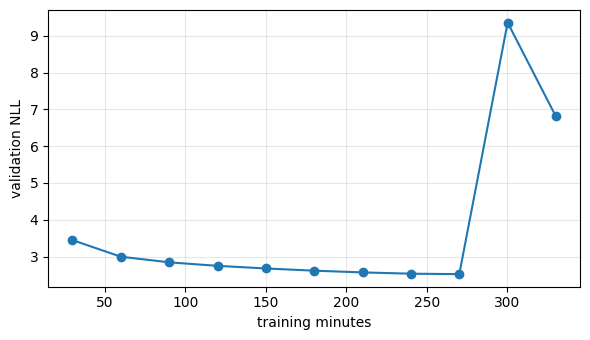

In [10]:
# =====================================================================================
# 10. TRAINING SUMMARY
# =====================================================================================
history = json.load(open(f"{RUN_DIR}/history.json"))
print(f"{'step':>7} {'epoch':>6} {'min':>6} {'train loss*':>12} {'val NLL':>9} {'val ppl':>9}")
for r in history:
    print(f"{r['step']:>7} {r['epoch']:>6.2f} {r['elapsed_min']:>6} {r['train_loss']:>12.4f} {r['val_nll']:>9.4f} {r['val_ppl']:>9.2f}")
print("* train loss includes label smoothing 0.05; val NLL is the plain negative log-likelihood of the continuation tokens")
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(6, 3.5))
    plt.plot([r["elapsed_min"] for r in history], [r["val_nll"] for r in history], marker="o")
    plt.xlabel("training minutes"); plt.ylabel("validation NLL"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(f"{WORK}/val_curve.png", dpi=120); plt.show()
except Exception as e:
    print("plot skipped:", e)

In [11]:
# =====================================================================================
# 11. LOAD BEST MODEL + DECODING SWEEP (BERTScore on held-out validation prompts)
# =====================================================================================
ck = torch.load(f"{RUN_DIR}/best.pt", map_location="cpu", weights_only=False)
cfg = EDConfig(**ck["cfg"])
model = EncDecLM(cfg)
model.load_state_dict(ck["model"])
model.to(DEV).eval()
IS_WS = make_word_start_table(tok.id_to_token, DEV)
print(f"loaded best checkpoint: step {ck['step']} | val NLL {ck['val_nll']:.4f} (ppl {math.exp(ck['val_nll']):.2f}) | cache parity ok: {CACHE_OK}")

def gen_texts(prompts, bs=32, **kw):
    outs = []
    for i in range(0, len(prompts), bs):
        with torch.autocast("cuda", dtype=torch.float16):
            ids = generate(model, prompts[i:i + bs], IS_WS, use_cache=CACHE_OK, **kw)
        outs += [" ".join(tok.decode(x).split()[:128]) for x in ids]
    return outs

def rep4(text):                                           # share of repeated 4-grams (loops show up here)
    w = text.split()
    g = [tuple(w[i:i + 4]) for i in range(len(w) - 3)]
    return 1 - len(set(g)) / max(len(g), 1)

va = eddata.load_split(DATA_DIR, "va")
sel = np.linspace(0, len(va["enc"]) - 1, 256).astype(int)
val_prompts = [va["enc"][i, :va["encl"][i]].tolist() for i in sel]
val_refs = [" ".join(tok.decode(va["tgt"][i, :va["tgtl"][i]].tolist()).split()) for i in sel]

CONFIGS = {
    "greedy (plain, like v1)":      dict(temperature=0.0),
    "greedy + 4-gram block":        dict(temperature=0.0, no_repeat_ngram=4),
    "greedy + 3-gram + rep 1.1":    dict(temperature=0.0, no_repeat_ngram=3, rep_penalty=1.1),
    "greedy + 3-gram + rep 1.2":    dict(temperature=0.0, no_repeat_ngram=3, rep_penalty=1.2),
    "top-k 40, T 0.7, 4-gram":      dict(temperature=0.7, top_k=40, no_repeat_ngram=4, seed=0),
    "top-p 0.9, T 0.8, 4-gram":     dict(temperature=0.8, top_p=0.9, no_repeat_ngram=4, seed=0),
}
scorer = None
try:
    try:
        from bert_score import BERTScorer
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bert-score"], check=True)
        from bert_score import BERTScorer
    scorer = BERTScorer(lang="en", model_type="roberta-large", device="cuda")
except Exception as e:
    print("BERTScore unavailable (", repr(e)[:100], ") -> falling back to the default decoding config")

sweep = {}
for name, kw in CONFIGS.items():
    t0 = time.time()
    outs = gen_texts(val_prompts, **kw)
    f1 = float(scorer.score(outs, val_refs)[2].mean()) if scorer is not None else float("nan")
    sweep[name] = dict(f1=f1, rep4=float(np.mean([rep4(o) for o in outs])), words=float(np.mean([len(o.split()) for o in outs])), kw=kw)
    print(f"{name:<30} BERTScore-F1 {f1:.4f} | repeated 4-grams {sweep[name]['rep4']:.3f} | words {sweep[name]['words']:.0f} | {time.time() - t0:.0f}s")

if scorer is not None:
    BEST_NAME = max(sweep, key=lambda n: sweep[n]["f1"])
else:
    BEST_NAME = "greedy + 3-gram + rep 1.1"
BEST_KW = CONFIGS[BEST_NAME]
print("\nSELECTED DECODING:", BEST_NAME, BEST_KW)
print("\nexample (validation prompt tail -> generated vs reference):")
ex = gen_texts(val_prompts[:1], **BEST_KW)[0]
print("PROMPT END :", tok.decode(val_prompts[0][-40:]))
print("GENERATED  :", ex[:500])
print("REFERENCE  :", val_refs[0][:500])
del scorer
torch.cuda.empty_cache()

loaded best checkpoint: step 17554 | val NLL 2.5204 (ppl 12.43) | cache parity ok: True
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.1 MB/s eta 0:00:00


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


greedy (plain, like v1)        BERTScore-F1 0.8227 | repeated 4-grams 0.597 | words 127 | 30s
greedy + 4-gram block          BERTScore-F1 0.8422 | repeated 4-grams 0.000 | words 128 | 28s
greedy + 3-gram + rep 1.1      BERTScore-F1 0.8413 | repeated 4-grams 0.000 | words 128 | 28s
greedy + 3-gram + rep 1.2      BERTScore-F1 0.8421 | repeated 4-grams 0.000 | words 128 | 28s
top-k 40, T 0.7, 4-gram        BERTScore-F1 0.8422 | repeated 4-grams 0.000 | words 128 | 29s
top-p 0.9, T 0.8, 4-gram       BERTScore-F1 0.8415 | repeated 4-grams 0.000 | words 128 | 29s

SELECTED DECODING: top-k 40, T 0.7, 4-gram {'temperature': 0.7, 'top_k': 40, 'no_repeat_ngram': 4, 'seed': 0}

example (validation prompt tail -> generated vs reference):
PROMPT END :  has elected not to subscribe during leave, the amount of subscription payable shall be proportionate to the number of days spent on duty in the month.. A fraction of a rupee shall be rounded to the nearest whole
GENERATED  : rupee. (10) Where the amo

In [12]:
# =====================================================================================
# 12. TEST INFERENCE -> prediction.json -> submission.zip
# =====================================================================================
import zipfile
ids_order = list(test_data.keys())
test_prompts = [tok.encode(test_data[k]["text"]) for k in ids_order]
t0 = time.time()
preds = {}
BS = 32
for i in range(0, len(ids_order), BS):
    texts = gen_texts(test_prompts[i:i + BS], bs=BS, **BEST_KW)
    for k, t in zip(ids_order[i:i + BS], texts):
        preds[k] = {"text": t}
    if (i // BS) % 5 == 0:
        print(f"  {min(i + BS, len(ids_order))}/{len(ids_order)} done | {(time.time() - t0) / 60:.1f} min")

with open(f"{WORK}/prediction.json", "w", encoding="utf-8") as f:
    json.dump(preds, f, ensure_ascii=False)
with zipfile.ZipFile(f"{WORK}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{WORK}/prediction.json", arcname="prediction.json")

wc = [len(preds[k]["text"].split()) for k in ids_order]
print("\n" + "=" * 66)
print("ids complete & identical to official ids :", set(preds) == set(test_data) and len(preds) == len(test_data))
print(f"words per prediction: min {min(wc)} | mean {np.mean(wc):.1f} | max {max(wc)} | exactly 128: {sum(w == 128 for w in wc)}/{len(wc)}")
print("prompt text leaked into prediction?      :", any(test_data[k]["text"][-60:] in preds[k]["text"] for k in ids_order[:200]))
print("repeated 4-gram share (lower = fewer loops):", round(float(np.mean([rep4(preds[k]["text"]) for k in ids_order])), 4))
print("zip contents:", zipfile.ZipFile(f"{WORK}/submission.zip").namelist())
print("=" * 66)
print("\nSAMPLE (id 1):\n", preds[ids_order[0]]["text"][:600])
assert all(w <= 128 for w in wc)

  32/1000 done | 0.0 min
  192/1000 done | 0.1 min
  352/1000 done | 0.3 min
  512/1000 done | 0.4 min
  672/1000 done | 0.5 min
  832/1000 done | 0.6 min
  992/1000 done | 0.7 min

ids complete & identical to official ids : True
words per prediction: min 128 | mean 128.0 | max 128 | exactly 128: 1000/1000
prompt text leaked into prediction?      : False
repeated 4-gram share (lower = fewer loops): 0.0
zip contents: ['prediction.json']

SAMPLE (id 1):
 well settled that if the proceedings are not quashed, consequential order of dismissal can be passed on the ground of laches and failure to do so. If the appellant was aggrieved by the order of the High Court dated 8th September, 2000, the appellant was required to have raised the issue of limitation. That apart, it is also well settled that delay in filing the writ petition has no relevance. It is true that the State Government has not been able to make out any case. But in the instant case, it would not be proper to issue show any show

In [13]:
# =====================================================================================
# 13. PACKAGE THE MODEL FOR PHASES 2-7 (weights + code + tokenizer + config)
# =====================================================================================
PKG = f"{WORK}/phase1_encdec_v2"
os.makedirs(PKG, exist_ok=True)
shutil.copy(f"{RUN_DIR}/best.pt", f"{PKG}/best.pt")
for fn in ("edmodel.py", "eddata.py", "train_ed.py"):
    shutil.copy(f"{CODE_DIR}/{fn}", f"{PKG}/{fn}")
for fn in ("a1_tokenization.py", "vocab.json", "merges.txt"):
    shutil.copy(f"{TOK_DIR}/{fn}", f"{PKG}/{fn}")
info = dict(model_cfg=MODEL_CFG, params=n_total, best_val_nll=ck["val_nll"], best_step=ck["step"],
            decoding=dict(name=BEST_NAME, **BEST_KW), sweep={k: dict(f1=v["f1"], rep4=v["rep4"]) for k, v in sweep.items()},
            launch=dict(nproc=CHOSEN[0], micro_bs=CHOSEN[1], accum=CHOSEN[2], train_budget_s=TRAIN_BUDGET_S))
json.dump(info, open(f"{PKG}/info.json", "w"), indent=1)
shutil.copy(f"{RUN_DIR}/history.json", f"{PKG}/history.json")
print("packaged ->", PKG, os.listdir(PKG))
print(f"\nTOTAL NOTEBOOK TIME: {(time.time() - NB_START) / 3600:.2f} h")
print("Upload  /kaggle/working/submission.zip  to Codabench (prediction.json is at the zip root).")

packaged -> /kaggle/working/phase1_encdec_v2 ['a1_tokenization.py', 'history.json', 'train_ed.py', 'edmodel.py', 'eddata.py', 'best.pt', 'merges.txt', 'info.json', 'vocab.json']

TOTAL NOTEBOOK TIME: 5.82 h
Upload  /kaggle/working/submission.zip  to Codabench (prediction.json is at the zip root).
